# F26-12 Phase 2: Data Collection and Preparation
Can Early Training Dynamics Predict Out-of-Distribution Generalization?




In [ ]:
import os, gzip, tarfile, colorsys, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset

SEED = 0
ROOT = "data"
P_GRID = [0.10, 0.50, 0.70, 0.90, 0.95, 0.99]
N_TRAIN, N_VAL = 50000, 10000
os.makedirs(ROOT, exist_ok=True)

## 1. Colored MNIST: collection

In [ ]:
MNIST_BASES = ["https://ossci-datasets.s3.amazonaws.com/mnist/",
               "https://storage.googleapis.com/cvdf-datasets/mnist/"]
MNIST_FILES = {"xtr": "train-images-idx3-ubyte.gz", "ytr": "train-labels-idx1-ubyte.gz",
               "xte": "t10k-images-idx3-ubyte.gz", "yte": "t10k-labels-idx1-ubyte.gz"}


def fetch(fname):
    path = os.path.join(ROOT, "mnist", fname)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        err = None
        for base in MNIST_BASES:
            try:
                urllib.request.urlretrieve(base + fname, path)
                return path
            except Exception as e:
                err = e
        raise err
    return path


def read_idx(path):
    with gzip.open(path, "rb") as f:
        data = f.read()
    ndim = data[3]
    shape = tuple(int.from_bytes(data[4 + 4 * i: 8 + 4 * i], "big") for i in range(ndim))
    return np.frombuffer(data, np.uint8, offset=4 + 4 * ndim).reshape(shape)


def load_mnist():
    d = {k: read_idx(fetch(v)) for k, v in MNIST_FILES.items()}
    return d["xtr"], d["ytr"].astype(np.int64), d["xte"], d["yte"].astype(np.int64)

In [ ]:
x_all, y_all, x_te, y_te = load_mnist()
print(x_all.shape, y_all.shape, x_te.shape, y_te.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


### Cleaning checks
MNIST ships clean, so the checks confirm dtype, pixel range, label coverage and absence of missing values rather than repair anything.

In [ ]:
for x, y in [(x_all, y_all), (x_te, y_te)]:
    assert x.dtype == np.uint8 and x.min() == 0 and x.max() == 255
    assert len(x) == len(y) and set(np.unique(y)) == set(range(10))
print("MNIST checks passed")

MNIST checks passed


### Splits
The 60,000 official training images are split at random into train and an in-distribution validation set. The official 10,000 test images are used for in-distribution and out-of-distribution testing.

In [ ]:
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(x_all))
tr_idx, va_idx = perm[:N_TRAIN], perm[N_TRAIN:N_TRAIN + N_VAL]
x_tr, y_tr, x_va, y_va = x_all[tr_idx], y_all[tr_idx], x_all[va_idx], y_all[va_idx]
SPLITS = {"train": (x_tr, y_tr), "val": (x_va, y_va), "test": (x_te, y_te)}
print({k: len(v[1]) for k, v in SPLITS.items()})

{'train': 50000, 'val': 10000, 'test': 10000}


### Shortcut construction
Each class has one fixed colour (10 evenly spaced hues). With probability p an image receives the colour of its true class; otherwise it receives one of the other nine colours uniformly. So p is the colour-label agreement: p = 0.10 makes colour independent of the label (no shortcut), p = 0.99 is a near-perfect shortcut, and p = 0 reverses it. Only the digit pixels are tinted; the background stays black.

In [ ]:
PALETTE = np.array([colorsys.hsv_to_rgb(i / 10, 1.0, 1.0) for i in range(10)], dtype=np.float32)


def assign_colors(labels, p, rng):
    agree = rng.rand(len(labels)) < p
    other = (labels + rng.randint(1, 10, len(labels))) % 10
    return np.where(agree, labels, other)


def colorize(images, color_idx):
    x = images[:, None, :, :].astype(np.float32) / 255.0
    return x * PALETTE[color_idx][:, :, None, None]

In [ ]:
COLORS = {}
for p in P_GRID:
    r = np.random.RandomState(SEED + int(round(p * 1000)))
    for split, (_, y) in SPLITS.items():
        COLORS[f"{split}_p{p:.2f}"] = assign_colors(y, p, r)
r = np.random.RandomState(SEED + 7)
COLORS["test_reversed"] = assign_colors(y_te, 0.0, r)
COLORS["test_uncorrelated"] = assign_colors(y_te, 0.1, r)
np.savez_compressed(os.path.join(ROOT, "colored_mnist_colors.npz"),
                    tr_idx=tr_idx, va_idx=va_idx, **COLORS)
print(len(COLORS), "colour assignments saved")

20 colour assignments saved


Only the colour index per image is stored (a few hundred KB); images are tinted on the fly, so all shortcut strengths share one copy of MNIST.

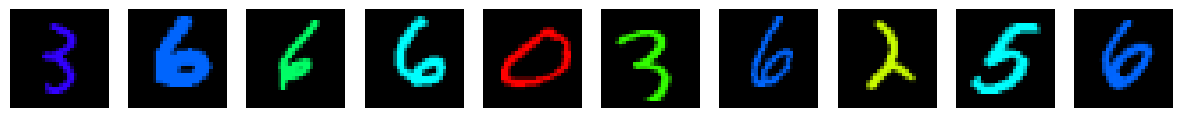

In [ ]:
sample = colorize(x_tr[:10000], COLORS["train_p0.50"][:10000])
MEAN = sample.mean(axis=(0, 2, 3))[:, None, None].astype(np.float32)
STD = sample.std(axis=(0, 2, 3))[:, None, None].astype(np.float32)


fig, axes = plt.subplots(1, 10, figsize=(15, 1.8))
for idx in range(10):
    axes[idx].imshow(sample[idx].transpose(1, 2, 0))
    axes[idx].axis("off")
plt.show()

del sample


class ColoredMNIST(Dataset):
    def __init__(self, images, labels, color_idx):
        self.images, self.labels, self.color_idx = images, labels, color_idx

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = colorize(self.images[i:i + 1], self.color_idx[i:i + 1])[0]
        return torch.from_numpy((x - MEAN) / STD), int(self.labels[i]), int(self.color_idx[i])


def make_dataset(split, key):
    x, y = SPLITS[split]
    return ColoredMNIST(x, y, COLORS[f"{split}_{key}"])

(3, 28, 28) 3 3


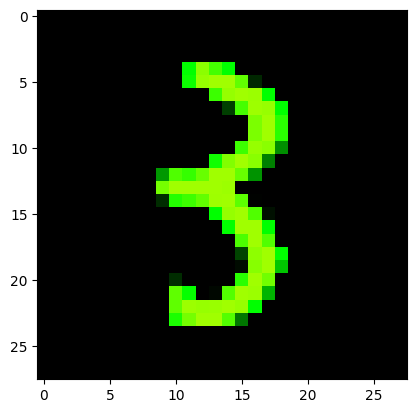

In [ ]:
x0, y0, c0 = make_dataset("train", "p0.90")[0]
print(tuple(x0.shape), y0, c0)

plt.imshow(x0.permute(1, 2, 0))
plt.show()

## 2. Colored MNIST: EDA

In [ ]:
print(pd.Series(y_tr).value_counts().sort_index().to_frame("train_count").T)

                0     1     2     3     4     5     6     7     8     9
train_count  4917  5629  4984  5105  4901  4531  4907  5227  4837  4962


Colour-label agreement per set. A classifier that outputs the class whose colour it sees has accuracy equal to this agreement, so the table is also the accuracy of a pure-shortcut model.

In [ ]:
rows = []
for p in P_GRID:
    k = f"p{p:.2f}"
    row = {"target_p": p}
    for split, (_, y) in SPLITS.items():
        a = np.mean(COLORS[f"{split}_{k}"] == y)
        tol = 4 * np.sqrt(p * (1 - p) / len(y)) + 1e-9
        assert abs(a - p) <= tol, (split, p, a)
        row[split] = round(a, 4)
    rows.append(row)
agreement = pd.DataFrame(rows).set_index("target_p")
agreement["test_reversed"] = round(np.mean(COLORS["test_reversed"] == y_te), 4)
agreement["test_uncorrelated"] = round(np.mean(COLORS["test_uncorrelated"] == y_te), 4)
agreement

,train,val,test,test_reversed,test_uncorrelated
target_p,,,,,
0.10,0.1022,0.0993,0.1005,0.0,0.1
0.50,0.5018,0.4996,0.5015,0.0,0.1
0.70,0.7066,0.6984,0.7048,0.0,0.1
0.90,0.9013,0.9035,0.8999,0.0,0.1
0.95,0.9486,0.9512,0.9495,0.0,0.1
0.99,0.9899,0.9885,0.9885,0.0,0.1


In [ ]:
print(pd.crosstab(y_tr, COLORS["train_p0.90"], normalize="index").round(2))
print(pd.crosstab(y_te, COLORS["test_reversed"], normalize="index").round(2))

col_0     0     1     2     3     4     5     6     7     8     9
row_0                                                            
0      0.90  0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.01
1      0.01  0.90  0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.01
2      0.01  0.01  0.90  0.01  0.01  0.01  0.01  0.01  0.01  0.01
3      0.01  0.01  0.01  0.90  0.01  0.01  0.01  0.01  0.01  0.01
4      0.01  0.01  0.01  0.01  0.90  0.01  0.01  0.01  0.01  0.01
5      0.01  0.01  0.01  0.01  0.01  0.90  0.01  0.01  0.01  0.01
6      0.01  0.01  0.01  0.01  0.01  0.01  0.91  0.01  0.01  0.01
7      0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.91  0.01  0.01
8      0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.91  0.01
9      0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.01  0.89
col_0     0     1     2     3     4     5     6     7     8     9
row_0                                                            
0      0.00  0.12  0.10  0.12  0.11  0.11  0.11  0.11  0.12  0.09
1      0.1

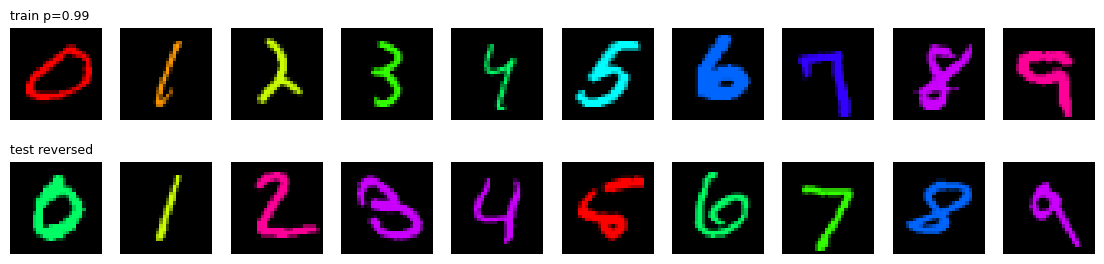

In [ ]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for row, (title, x, y, c) in enumerate([("train p=0.99", x_tr, y_tr, COLORS["train_p0.99"]),
                                         ("test reversed", x_te, y_te, COLORS["test_reversed"])]):
    for d in range(10):
        i = np.where(y == d)[0][0]
        axes[row, d].imshow(colorize(x[i:i + 1], c[i:i + 1])[0].transpose(1, 2, 0))
        axes[row, d].axis("off")
    axes[row, 0].set_title(title, fontsize=9, loc="left")
plt.show()

Shape-only reference: a linear classifier on grayscale pixels, to confirm the digit shape alone carries the label.

In [ ]:
from sklearn.linear_model import LogisticRegression
n = min(10000, len(x_tr))
clf = LogisticRegression(max_iter=200)
clf.fit(x_tr[:n].reshape(n, -1) / 255.0, y_tr[:n])
print("shape-only val accuracy:", round(clf.score(x_va.reshape(len(x_va), -1) / 255.0, y_va), 4))

shape-only val accuracy: 0.9021


## 3. Waterbirds: collection
Source: the original Waterbirds release (Sagawa et al., 2020), built from CUB-200-2011 bird photos pasted onto Places backgrounds. Label y: 0 landbird, 1 waterbird. Background place: 0 land, 1 water. Group = 2y + place.

In [ ]:
WB_URLS = ["https://downloads.cs.stanford.edu/nlp/data/dro/waterbird_complete95_forest2water2.tar.gz",
           "https://nlp.stanford.edu/data/dro/waterbird_complete95_forest2water2.tar.gz"]
WB_BASE = os.path.join(ROOT, "waterbirds")
WB_NAME = "waterbird_complete95_forest2water2"


def download_waterbirds():
    out = os.path.join(WB_BASE, WB_NAME)
    if os.path.isdir(out):
        return out
    os.makedirs(WB_BASE, exist_ok=True)
    tar_path = os.path.join(WB_BASE, WB_NAME + ".tar.gz")
    err = None
    for url in WB_URLS:
        try:
            urllib.request.urlretrieve(url, tar_path)
            break
        except Exception as e:
            err = e
    else:
        raise err
    with tarfile.open(tar_path) as t:
        t.extractall(WB_BASE)
    return out


1. Group 0: Landbird on Land (majority group)
2. Group 1: Landbird on Water (minority group)
3. Group 2: Waterbird on Land (minority group)
4. Group 3: Waterbird on Water (majority group)




In [ ]:
WB_DIR = download_waterbirds()
meta = pd.read_csv(os.path.join(WB_DIR, "metadata.csv"))
meta["group"] = 2 * meta["y"] + meta["place"]
print(meta.shape)
meta.head()

/tmp/ipykernel_6560/2755387420.py:23: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(WB_BASE)


(11788, 7)


,img_id,img_filename,y,split,place,place_filename,group
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,2,1,/o/ocean/00002178.jpg,3
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,1,/l/lake/natural/00000065.jpg,3
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,2,0,/b/bamboo_forest/00000131.jpg,2
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,1,/o/ocean/00001268.jpg,3
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,1,/o/ocean/00003147.jpg,3


### Cleaning checks
No repair is expected; the checks confirm no missing values, no duplicate images, valid labels, and that every listed file exists.

In [ ]:
assert meta.isna().sum().sum() == 0
assert meta["img_filename"].is_unique
assert set(meta["y"]) <= {0, 1} and set(meta["place"]) <= {0, 1} and set(meta["split"]) <= {0, 1, 2}
missing = [f for f in meta["img_filename"] if not os.path.exists(os.path.join(WB_DIR, f))]
assert not missing, f"{len(missing)} files missing"
print("Waterbirds checks passed")

Waterbirds checks passed


In [ ]:
assert len(meta) == 11788
assert meta["split"].value_counts().sort_index().tolist() == [4795, 1199, 5794]
assert meta[meta.split == 0]["group"].value_counts().sort_index().tolist() == [3498, 184, 56, 1057]

### Splits
The official split is kept (0 train, 1 validation, 2 test). In the official release the validation and test sets are balanced across backgrounds, so they are already shifted relative to training. To have an in-distribution reference set (needed by ATC and Agreement-on-the-Line), 15% of each training group is held out as `id_holdout`.

In [ ]:
from sklearn.model_selection import train_test_split
GROUPS = {0: "landbird/land", 1: "landbird/water", 2: "waterbird/land", 3: "waterbird/water"}
meta["subset"] = meta["split"].map({0: "train_fit", 1: "val", 2: "test"})
tr = meta[meta.split == 0]
_, hold = train_test_split(tr.index, test_size=0.15, stratify=tr["group"], random_state=SEED)
meta.loc[hold, "subset"] = "id_holdout"
pd.crosstab(meta["subset"], meta["group"].map(GROUPS), margins=True)

group,landbird/land,landbird/water,waterbird/land,waterbird/water,All
subset,,,,,
id_holdout,525,28,8,159,720
test,2255,2255,642,642,5794
train_fit,2973,156,48,898,4075
val,467,466,133,133,1199
All,6220,2905,831,1832,11788


### Preprocessing

In [ ]:
IM_MEAN = np.array([0.485, 0.456, 0.406], np.float32)[:, None, None]
IM_STD = np.array([0.229, 0.224, 0.225], np.float32)[:, None, None]


def preprocess(img, resize=256, size=224):
    img = img.convert("RGB").resize((resize, resize), Image.BILINEAR)
    o = (resize - size) // 2
    img = img.crop((o, o, o + size, o + size))
    x = np.asarray(img, np.float32).transpose(2, 0, 1) / 255.0
    return (x - IM_MEAN) / IM_STD


class Waterbirds(Dataset):
    def __init__(self, root, df):
        self.root, self.df = root, df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        x = preprocess(Image.open(os.path.join(self.root, r["img_filename"])))
        return torch.from_numpy(x), int(r["y"]), int(r["group"])


wb = {s: Waterbirds(WB_DIR, meta[meta.subset == s]) for s in ["train_fit", "id_holdout", "val", "test"]}
x0, y0, g0 = wb["train_fit"][0]
print(tuple(x0.shape), y0, g0)

(3, 224, 224) 1 3


## 4. Waterbirds: EDA

In [ ]:
trn = meta[meta.split == 0]
print("class balance (train):", trn["y"].value_counts(normalize=True).round(3).to_dict())
print("P(water background | waterbird):", round(trn[trn.y == 1]["place"].mean(), 3))
print("P(land background | landbird):", round(1 - trn[trn.y == 0]["place"].mean(), 3))
print("minority-group share of train:", round(trn["group"].isin([1, 2]).mean(), 3))

class balance (train): {0: 0.768, 1: 0.232}
P(water background | waterbird): 0.95
P(land background | landbird): 0.95
minority-group share of train: 0.05


In [ ]:
rs = np.random.RandomState(SEED)
sizes = [Image.open(os.path.join(WB_DIR, f)).size
         for f in rs.choice(meta["img_filename"], size=min(300, len(meta)), replace=False)]
print(pd.DataFrame(sizes, columns=["width", "height"]).describe().loc[["min", "50%", "max"]])

     width  height
min  121.0   170.0
50%  500.0   375.0
max  500.0   500.0


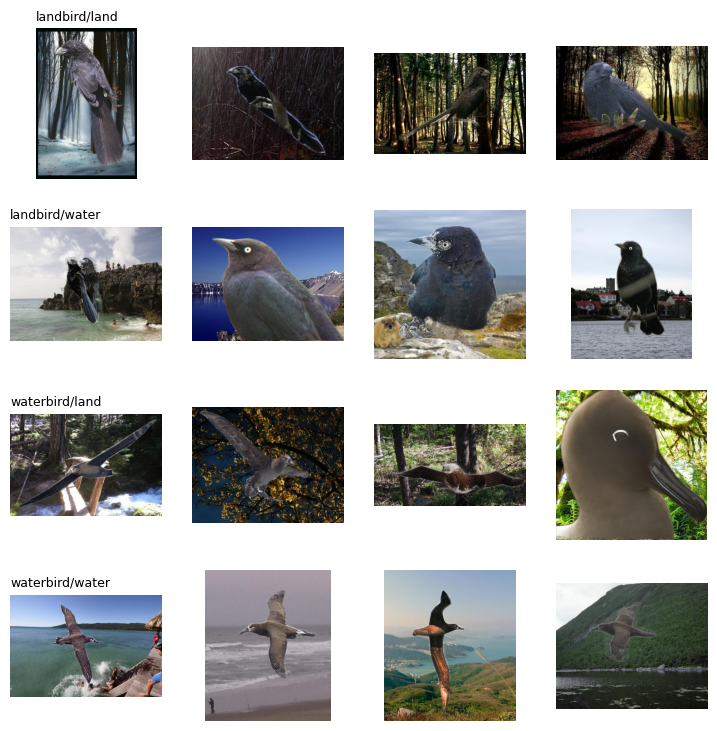

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for g in range(4):
    files = meta[(meta.subset == "train_fit") & (meta.group == g)]["img_filename"].head(4)
    for j, f in enumerate(files):
        axes[g, j].imshow(Image.open(os.path.join(WB_DIR, f)))
        axes[g, j].axis("off")
    axes[g, 0].set_title(GROUPS[g], fontsize=9, loc="left")
plt.show()

## 5. Final dataset summary

In [ ]:
summary = pd.DataFrame([
    {"dataset": "Colored MNIST", "split": s, "images": len(SPLITS[s][1]),
     "shape": "3x28x28", "classes": 10,
     "variants": "p in " + str(P_GRID) + (" + reversed, uncorrelated" if s == "test" else "")}
    for s in SPLITS
] + [
    {"dataset": "Waterbirds", "split": s, "images": len(wb[s]), "shape": "3x224x224",
     "classes": 2, "variants": "4 groups"}
    for s in wb
])
summary

,dataset,split,images,shape,classes,variants
0,Colored MNIST,train,50000,3x28x28,10,"p in [0.1, 0.5, 0.7, 0.9, 0.95, 0.99]"
1,Colored MNIST,val,10000,3x28x28,10,"p in [0.1, 0.5, 0.7, 0.9, 0.95, 0.99]"
2,Colored MNIST,test,10000,3x28x28,10,"p in [0.1, 0.5, 0.7, 0.9, 0.95, 0.99] + revers..."
3,Waterbirds,train_fit,4075,3x224x224,2,4 groups
4,Waterbirds,id_holdout,720,3x224x224,2,4 groups
5,Waterbirds,val,1199,3x224x224,2,4 groups
6,Waterbirds,test,5794,3x224x224,2,4 groups


# Phase 3: Initial implementation and experiments

This section trains a small CNN on two Colored MNIST conditions: **p = 0.99** (strong colour shortcut) and **p = 0.10** (approximately no colour-label relationship). It records validation behaviour at 5%, 10%, 15%, 20%, and 100% of the planned optimizer steps.

The initial Phase 3 experiment uses one fixed seed and five epochs to keep the first run manageable. These are preliminary results, not final conclusions. Waterbirds and additional seeds can be added after this pipeline runs successfully.

## 6. Training setup

- **Model:** small CNN trained from scratch.
- **Optimizer:** Adam; **loss:** cross-entropy.
- **Batch size:** 128; **epochs:** 5; **seed:** 0.
- **Early signal:** relative accuracy drop when the colour cue is neutralized on validation images.
- **Calibration:** a simple ATC-style confidence threshold calibrated using labeled in-distribution validation data. We compare its OOD estimate with true OOD accuracy only for evaluation; real deployment would not have OOD labels.

In [ ]:
import random
import math
import time
from torch import nn
from torch.utils.data import DataLoader

# ---------- Settings for the Phase 3 experiment ----------
BATCH_SIZE = 128          # images per optimizer step
EPOCHS = 5                # total training length, fixed in advance for every model
LEARNING_RATE = 1e-3      # Adam learning rate
SEEDS = [0, 1, 2]         # one model is trained for every (p, seed) pair
P_VALUES = P_GRID         # [0.10, 0.50, 0.70, 0.90, 0.95, 0.99] from Phase 2
CKPT_FRACTIONS = [0.05, 0.10, 0.15, 0.20, 1.00]   # fractions of the total optimizer steps
RESULTS_DIR = "phase3_outputs"   # on Colab, change this to a Google Drive path
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Make the folders where results and checkpoint weights will be saved
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(os.path.join(RESULTS_DIR, "checkpoints"), exist_ok=True)


def set_seed(seed):
    # Reset every random number generator so that a run can be repeated exactly
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE, "| epochs:", EPOCHS, "| learning rate:", LEARNING_RATE)
print("p values:", P_VALUES, "| seeds:", SEEDS)

Device: cpu
Batch size: 128 | epochs: 5 | learning rate: 0.001
p values: [0.1, 0.5, 0.7, 0.9, 0.95, 0.99] | seeds: [0, 1, 2]


In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten()
        )
        self.classifier = nn.Sequential(
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


class NeutralizedColoredMNIST(Dataset):
    # Replace each coloured digit with a grayscale image repeated over RGB channels.
    # This removes the colour shortcut while preserving digit shape.
    def __init__(self, base_dataset):
        self.base = base_dataset

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        gray = self.base.images[i].astype(np.float32) / 255.0
        gray = np.repeat(gray[None, :, :], 3, axis=0)
        gray = (gray - MEAN) / STD
        return torch.from_numpy(gray.astype(np.float32)), int(self.base.labels[i]), int(self.base.color_idx[i])



def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=2 if os.name != "nt" else 0,
                      pin_memory=torch.cuda.is_available())

def evaluate(model, loader):
    # Returns the accuracy and the confidence (max softmax probability) of every prediction
    model.eval()
    correct = 0
    total = 0
    confidence_batches = []
    with torch.no_grad():
        for images, labels, _ in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            confidence, predictions = probabilities.max(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
            confidence_batches.append(confidence.cpu().numpy())
    confidences = np.concatenate(confidence_batches)
    return correct / total, confidences

In [ ]:
# Validation images with fresh random colours (p = 0.1 means colour is independent of the label).
# This stays inside the colour range the model saw in training, unlike the grayscale version.
random_color_rng = np.random.RandomState(SEED + 11)
COLORS["val_random"] = assign_colors(y_va, 0.1, random_color_rng)

# Check: colour-label agreement should be close to 0.1
print("val_random agreement:", np.mean(COLORS["val_random"] == y_va))

val_random agreement: 0.1006


## 7. One-model Trainer, grid runner and helper functions

The checkpoint percentages refer to the fraction of planned optimizer updates completed, not the fraction of epochs. At each checkpoint, we measure validation accuracy on the normal validation images and after neutralizing colour. The difference is a shortcut-reliance proxy, not a causal proof.

In [ ]:
RESULTS_PATH = os.path.join(RESULTS_DIR, "phase3_results.csv")


def get_checkpoint_steps(total_steps):
    # Turns the fractions into step numbers, for example 0.05 -> step 98 with label "ck05"
    steps = {}
    for fraction in CKPT_FRACTIONS:
        step = max(1, math.ceil(total_steps * fraction))
        label = "ck" + str(int(round(fraction * 100))).zfill(2)
        steps[step] = label
    return steps


def relative_drop(normal_acc, changed_acc):
    # How much accuracy is lost, divided by normal accuracy. Bigger means more colour reliance.
    return (normal_acc - changed_acc) / max(normal_acc, 1e-8)


def find_atc_threshold(id_confidence, id_accuracy):
    # ATC: choose the confidence value where the fraction of ID examples at or above it
    # is closest to the ID accuracy
    best_threshold = float(id_confidence[0])
    best_gap = float("inf")
    for threshold in np.unique(id_confidence):
        fraction_above = np.mean(id_confidence >= threshold)
        gap = abs(fraction_above - id_accuracy)
        if gap < best_gap:
            best_gap = gap
            best_threshold = float(threshold)
    return best_threshold


def train_one_model(p_value, seed):
    # Trains one SmallCNN and returns ONE row (a dictionary) describing this model
    set_seed(seed)
    key = f"p{p_value:.2f}"

    # Datasets and loaders
    train_dataset = make_dataset("train", key)
    val_dataset = make_dataset("val", key)
    neutral_val_dataset = NeutralizedColoredMNIST(val_dataset)
    random_val_dataset = make_dataset("val", "random")
    train_loader = make_loader(train_dataset, shuffle=True)
    val_loader = make_loader(val_dataset)
    neutral_val_loader = make_loader(neutral_val_dataset)
    random_val_loader = make_loader(random_val_dataset)

    # Model, optimizer, loss
    model = SmallCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.CrossEntropyLoss()

    # Total length is fixed in advance, so every model has the same checkpoint steps
    total_steps = len(train_loader) * EPOCHS
    checkpoint_steps = get_checkpoint_steps(total_steps)

    # Start the row with the model description
    row = {"dataset": "ColoredMNIST", "architecture": "SmallCNN", "p": p_value,
           "seed": seed, "epochs": EPOCHS, "total_steps": total_steps}

    step = 0
    model.train()
    for epoch in range(EPOCHS):
        for images, labels, _ in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            # One optimizer update
            optimizer.zero_grad()
            logits = model(images)
            loss = loss_function(logits, labels)
            loss.backward()
            optimizer.step()
            step += 1

            # At a checkpoint step: measure the early signals and save the weights
            if step in checkpoint_steps:
                label = checkpoint_steps[step]
                val_acc, _ = evaluate(model, val_loader)
                neutral_acc, _ = evaluate(model, neutral_val_loader)
                random_acc, _ = evaluate(model, random_val_loader)

                row["val_acc_" + label] = val_acc
                row["neutral_acc_" + label] = neutral_acc
                row["reliance_neutral_" + label] = relative_drop(val_acc, neutral_acc)
                row["random_acc_" + label] = random_acc
                row["reliance_random_" + label] = relative_drop(val_acc, random_acc)

                weight_name = f"cnn_{key}_seed{seed}_{label}.pt"
                torch.save(model.state_dict(), os.path.join(RESULTS_DIR, "checkpoints", weight_name))
                print(f"  p={p_value:.2f} seed={seed} {label} (step {step}/{total_steps}): "
                      f"val={val_acc:.3f} neutral={neutral_acc:.3f} random={random_acc:.3f}")
                model.train()

    # After training: ATC threshold from the ID validation set (labels allowed here)
    id_val_accuracy, id_val_confidence = evaluate(model, val_loader)
    threshold = find_atc_threshold(id_val_confidence, id_val_accuracy)
    row["id_val_accuracy"] = id_val_accuracy
    row["atc_threshold"] = threshold

    # Evaluate on the three test sets: true accuracy, then ATC prediction using confidences only
    eval_sets = {
        "id_test": make_dataset("test", key),
        "reversed": make_dataset("test", "reversed"),
        "uncorrelated": make_dataset("test", "uncorrelated"),
    }
    for name in eval_sets:
        true_acc, confidence = evaluate(model, make_loader(eval_sets[name]))
        predicted_acc = float(np.mean(confidence >= threshold))
        row["true_acc_" + name] = true_acc
        row["atc_pred_" + name] = predicted_acc
        row["atc_error_" + name] = abs(predicted_acc - true_acc)

    return row


def run_grid(p_list, seed_list):
    # Runs every (seed, p) pair, skips pairs already saved, and saves the CSV after every run
    rows = []
    done = []
    if os.path.exists(RESULTS_PATH):
        saved = pd.read_csv(RESULTS_PATH)
        rows = saved.to_dict("records")
        for old_row in rows:
            done.append((round(old_row["p"], 2), int(old_row["seed"])))

    # Seeds are the outer loop so that a partial run still covers every p value
    for seed in seed_list:
        for p_value in p_list:
            if (round(p_value, 2), seed) in done:
                print("skip (already finished): p =", p_value, "seed =", seed)
                continue
            print("training: p =", p_value, "seed =", seed)
            start = time.time()
            row = train_one_model(p_value, seed)
            row["run_seconds"] = time.time() - start
            rows.append(row)
            pd.DataFrame(rows).to_csv(RESULTS_PATH, index=False)
            print("  finished in", round(row["run_seconds"], 1), "seconds")
    return pd.DataFrame(rows)

In [ ]:
# Run ONE model first and time it, so we can decide how big the grid can be
first_run_df = run_grid([0.99], [0])
seconds = first_run_df["run_seconds"].iloc[0]
print("One run took", round(seconds, 1), "seconds")
print("Estimated time for 18 runs:", round(seconds * 18 / 60, 1), "minutes")

training: p = 0.99 seed = 0
  p=0.99 seed=0 ck05 (step 98/1955): val=0.986 neutral=0.618 random=0.332
  p=0.99 seed=0 ck10 (step 196/1955): val=0.987 neutral=0.507 random=0.436
  p=0.99 seed=0 ck15 (step 294/1955): val=0.991 neutral=0.603 random=0.452
  p=0.99 seed=0 ck20 (step 391/1955): val=0.992 neutral=0.637 random=0.580
  p=0.99 seed=0 ck100 (step 1955/1955): val=0.996 neutral=0.865 random=0.787
  finished in 400.5 seconds
One run took 400.5 seconds
Estimated time for 18 runs: 120.2 minutes


In [ ]:
# Full grid: 6 p values x 3 seeds = 18 models. Finished runs are skipped automatically.
results_df = run_grid(P_VALUES, SEEDS)
print(len(results_df), "models in the results table")

skip (already finished): p = 0.1 seed = 0
skip (already finished): p = 0.5 seed = 0
skip (already finished): p = 0.7 seed = 0
skip (already finished): p = 0.9 seed = 0
skip (already finished): p = 0.95 seed = 0
skip (already finished): p = 0.99 seed = 0
skip (already finished): p = 0.1 seed = 1
skip (already finished): p = 0.5 seed = 1
skip (already finished): p = 0.7 seed = 1
skip (already finished): p = 0.9 seed = 1
skip (already finished): p = 0.95 seed = 1
skip (already finished): p = 0.99 seed = 1
skip (already finished): p = 0.1 seed = 2
skip (already finished): p = 0.5 seed = 2
skip (already finished): p = 0.7 seed = 2
skip (already finished): p = 0.9 seed = 2
skip (already finished): p = 0.95 seed = 2
skip (already finished): p = 0.99 seed = 2
18 models in the results table


# extra things to run for verification

In [ ]:
print(len(results_df)); print(results_df.groupby("p")["seed"].count())

# Remove the effect of p: subtract each p's average, then correlate what is left over
check_columns = ["reliance_random_ck10", "reliance_neutral_ck10", "atc_pred_reversed", "true_acc_reversed"]
residual_df = results_df.copy()
for column in check_columns:
    p_means = results_df.groupby("p")[column].transform("mean")
    residual_df[column] = results_df[column] - p_means
print(residual_df[check_columns].corr().round(3))

# Compare simple "predictors" of reversed accuracy by mean absolute error
# (the per-p lookup is in-sample, so it is optimistic: it is a reference, not a fair competitor)
per_p_mean = results_df.groupby("p")["true_acc_reversed"].transform("mean")
print("MAE, per-p average lookup (in-sample):", round(np.mean(np.abs(results_df["true_acc_reversed"] - per_p_mean)), 4))
print("MAE, ATC:", round(results_df["atc_error_reversed"].mean(), 4))

18
p
0.10    3
0.50    3
0.70    3
0.90    3
0.95    3
0.99    3
Name: seed, dtype: int64
                       reliance_random_ck10  reliance_neutral_ck10  \
reliance_random_ck10                  1.000                  0.272   
reliance_neutral_ck10                 0.272                  1.000   
atc_pred_reversed                    -0.727                 -0.508   
true_acc_reversed                     0.180                 -0.052   

                       atc_pred_reversed  true_acc_reversed  
reliance_random_ck10              -0.727              0.180  
reliance_neutral_ck10             -0.508             -0.052  
atc_pred_reversed                  1.000              0.226  
true_acc_reversed                  0.226              1.000  
MAE, per-p average lookup (in-sample): 0.004
MAE, ATC: 0.0105


# Plotting

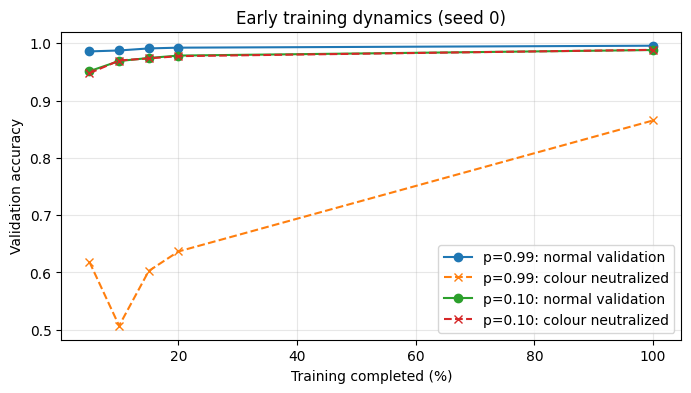

In [ ]:
# Reload from disk so this cell still works after a disconnect
results_df = pd.read_csv(RESULTS_PATH)

labels = ["ck05", "ck10", "ck15", "ck20", "ck100"]
x_values = [5, 10, 15, 20, 100]

plt.figure(figsize=(8, 4))
for p_value in [0.99, 0.10]:
    part = results_df[(results_df["p"] == p_value) & (results_df["seed"] == 0)]
    normal_curve = []
    neutral_curve = []
    for label in labels:
        normal_curve.append(part["val_acc_" + label].iloc[0])
        neutral_curve.append(part["neutral_acc_" + label].iloc[0])
    plt.plot(x_values, normal_curve, marker="o", label=f"p={p_value:.2f}: normal validation")
    plt.plot(x_values, neutral_curve, marker="x", linestyle="--", label=f"p={p_value:.2f}: colour neutralized")
plt.xlabel("Training completed (%)")
plt.ylabel("Validation accuracy")
plt.title("Early training dynamics (seed 0)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(RESULTS_DIR, "early_dynamics.png"), dpi=200, bbox_inches="tight")
plt.show()

## 8. ATC-style estimate and true OOD evaluation - ATC is computed inside train_one_model for every model.

For each trained model, we calibrate a confidence threshold on its own labeled in-distribution validation set. The threshold is selected so that the proportion of validation examples above it is as close as possible to the model's ID validation accuracy. We then apply that threshold to OOD examples without using their labels to make the estimate.

The true OOD accuracy is calculated afterward as an evaluation-only comparison. Here, reversed and uncorrelated test sets are available, so this notebook can measure estimation error.

In [ ]:
atc_columns = ["p", "seed", "atc_threshold",
               "atc_pred_reversed", "true_acc_reversed", "atc_error_reversed",
               "atc_pred_uncorrelated", "true_acc_uncorrelated", "atc_error_uncorrelated"]
atc_table = results_df[atc_columns].sort_values(["p", "seed"]).round(4)
display(atc_table)

,p,seed,atc_threshold,atc_pred_reversed,true_acc_reversed,atc_error_reversed,atc_pred_uncorrelated,true_acc_uncorrelated,atc_error_uncorrelated
1,0.10,0,0.7721,0.9886,0.9902,0.0016,0.9899,0.9901,0.0002
6,0.10,1,0.7790,0.9849,0.9869,0.0020,0.9833,0.9875,0.0042
12,0.10,2,0.7388,0.9866,0.9881,0.0015,0.9863,0.9878,0.0015
2,0.50,0,0.7777,0.9826,0.9868,0.0042,0.9844,0.9881,0.0037
7,0.50,1,0.7713,0.9814,0.9830,0.0016,0.9830,0.9855,0.0025
13,0.50,2,0.7339,0.9816,0.9827,0.0011,0.9812,0.9860,0.0048
3,0.70,0,0.7582,0.9778,0.9793,0.0015,0.9792,0.9811,0.0019
8,0.70,1,0.7763,0.9757,0.9763,0.0006,0.9773,0.9791,0.0018
14,0.70,2,0.6900,0.9830,0.9798,0.0032,0.9822,0.9819,0.0003
4,0.90,0,0.7644,0.9417,0.9426,0.0009,0.9479,0.9485,0.0006


## 9. Save a compact Phase 3 results table

The following table combines checkpoint dynamics with the final model's ATC-style estimates. Keep the generated CSV files and model checkpoints with the notebook when submitting or moving to Phase 4.

In [ ]:
# Average over seeds for each p
summary_columns = ["true_acc_id_test", "true_acc_reversed", "true_acc_uncorrelated",
                   "atc_error_reversed", "atc_error_uncorrelated",
                   "reliance_neutral_ck10", "reliance_random_ck10", "reliance_neutral_ck100"]
summary = results_df.groupby("p")[summary_columns].mean().round(4)
display(summary)
summary.to_csv(os.path.join(RESULTS_DIR, "phase3_summary_by_p.csv"))

# Spread across seeds, to show how much a single seed can vary
print("Std of reversed accuracy across seeds:")
print(results_df.groupby("p")["true_acc_reversed"].std().round(4))

# Sanity check: p = 0.99 must be clearly worse on the reversed set than p = 0.10
mean_reversed = results_df.groupby("p")["true_acc_reversed"].mean()
print("p=0.99 reversed:", round(mean_reversed[0.99], 4), "| p=0.10 reversed:", round(mean_reversed[0.10], 4))
assert mean_reversed[0.99] < mean_reversed[0.10] - 0.05, "Sanity check failed, investigate"
print("Sanity check passed")

# Optional first look (exploratory only, NOT a result: p drives everything and n is small)
print(results_df[["reliance_neutral_ck10", "reliance_random_ck10",
                  "atc_pred_reversed", "true_acc_reversed"]].corr().round(3))

,true_acc_id_test,true_acc_reversed,true_acc_uncorrelated,atc_error_reversed,atc_error_uncorrelated,reliance_neutral_ck10,reliance_random_ck10,reliance_neutral_ck100
p,,,,,,,,
0.10,0.9886,0.9884,0.9885,0.0017,0.0020,0.0009,0.0006,-0.0005
0.50,0.9894,0.9842,0.9865,0.0023,0.0037,0.0121,0.0107,0.0029
0.70,0.9911,0.9785,0.9807,0.0018,0.0013,0.0337,0.0315,0.0068
0.90,0.9923,0.9497,0.9550,0.0053,0.0048,0.1261,0.1229,0.0293
0.95,0.9943,0.9331,0.9404,0.0080,0.0091,0.1865,0.2306,0.0387
0.99,0.9966,0.7757,0.7992,0.0438,0.0340,0.4351,0.6076,0.1197


Std of reversed accuracy across seeds:
p
0.10    0.0017
0.50    0.0023
0.70    0.0019
0.90    0.0062
0.95    0.0124
0.99    0.0087
Name: true_acc_reversed, dtype: float64
p=0.99 reversed: 0.7757 | p=0.10 reversed: 0.9884
Sanity check passed
                       reliance_neutral_ck10  reliance_random_ck10  \
reliance_neutral_ck10                  1.000                 0.965   
reliance_random_ck10                   0.965                 1.000   
atc_pred_reversed                     -0.966                -0.986   
true_acc_reversed                     -0.949                -0.981   

                       atc_pred_reversed  true_acc_reversed  
reliance_neutral_ck10             -0.966             -0.949  
reliance_random_ck10              -0.986             -0.981  
atc_pred_reversed                  1.000              0.971  
true_acc_reversed                  0.971              1.000  


## Phase 3 limitations and next steps

1. Colored MNIST only, one architecture (SmallCNN), 3 seeds; Waterbirds, Prediction Depth, AGL and the gradient-starvation proxy are Phase 4.
2. Colour-neutralization accuracy drop is an interpretable shortcut-reliance proxy; it is not the full Prediction Depth (PD) method.
3. ATC's predicted OOD accuracy can be inaccurate when confidence does not transfer from ID to OOD data. Report both predicted and true OOD accuracy and the absolute estimation error.
4. Phase 4 should repeat runs across seeds and the full p grid, add a formal Prediction Depth implementation if feasible, and evaluate Waterbirds with group-wise accuracy (especially minority groups 1 and 2).
5. Do not report numerical results in the project report until these cells have actually run in the intended Colab runtime.